In [1]:
### New

In [2]:
import pandas as pd
from omegaconf import DictConfig
import omegaconf
import psycopg2

In [3]:
cfg = omegaconf.OmegaConf.load("../config.yaml")
conn = psycopg2.connect(**cfg.db)

## Create set of candidate queries

In [4]:
# Get searches
def load_searches(snapshot):
    if snapshot == "test":
        snapshot = 1
    query = f"""
    SELECT search_id, serp, queries.query_id, original_id, log_date
    FROM search_logs_normalized
    JOIN queries ON search_logs_normalized.query_id = queries.query_id
    WHERE log_date >= '{cfg["snapshots"][snapshot]["start_date"]}'
        AND log_date <= '{cfg["snapshots"][snapshot]["end_date"]}'
        AND is_structured is FALSE AND is_boolean is FALSE and has_doi is FALSE and was_clicked is TRUE;
    """
    searches = pd.read_sql_query(query, con=conn)
    searches = searches.drop_duplicates(subset=["search_id"])
    searches = searches.rename(columns={"log_date": "search_date"})
    return searches

In [5]:
def load_clicks(snapshot, searches):
    if snapshot == "test":
        snapshot = 1
    search_ids = list(searches["search_id"].unique())

    query = f"""
    SELECT *
    FROM tracker_logs
    WHERE search_id in {tuple(search_ids)}
        AND log_date >= '{cfg["snapshots"][snapshot]["start_date"]}'
        AND log_date <=  '{cfg["snapshots"][snapshot]["end_date"]}'
        AND (entry_type = 'get-pdf' OR entry_type = 'works')
    """
    clicks = pd.read_sql_query(query, con=conn)
    clicks = clicks.rename(columns={"log_date": "click_date"})

    searches_query_ids = (
        searches[["query_id", "search_id"]].set_index("search_id").to_dict()["query_id"]
    )
    clicks["query_id"] = clicks["search_id"].map(searches_query_ids)
    return clicks

In [6]:
def filter_candidate_queries(clicks, searches):
    clicks = clicks.merge(
        searches[["search_id", "search_date"]],
        left_on="search_id",
        right_on="search_id",
        how="left",
    )
    print("Clicks before 24h filter:", len(clicks))
    # Only keep clicks that happened within 1 day of the search
    # mask = (clicks["click_date"] >= clicks["search_date"]) & (clicks["click_date"] <= clicks["search_date"] + pd.Timedelta(days=1))
    mask = clicks["click_date"] <= clicks["search_date"] + pd.Timedelta(days=1)
    clicks = clicks[mask]

    print("Clicks after 24h filter:", len(clicks))

    click_stats = (
        clicks.groupby("query_id").count().reset_index()[["query_id", "search_id"]]
    )
    candidate_queries = click_stats[click_stats["search_id"] > 30]
    print("Candidate queries with at least 30 clicks:", len(candidate_queries))
    return candidate_queries

In [7]:
candidates = []
for snapshot in [1, 2, 3]:
    searches = load_searches(snapshot)
    clicks = load_clicks(snapshot, searches)
    candidate_queries = filter_candidate_queries(clicks, searches)
    candidate_queries.rename(
        columns={"search_id": f"clicks-snapshot-{snapshot}"}, inplace=True
    )
    candidates.append(candidate_queries)

/tmp/ipykernel_2182348/3952583378.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  searches = pd.read_sql_query(query, con=conn)
/tmp/ipykernel_2182348/3466241771.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  clicks = pd.read_sql_query(query, con=conn)


Clicks before 24h filter: 552032
Clicks after 24h filter: 390315
Candidate queries with at least 30 clicks: 463


/tmp/ipykernel_2182348/3952583378.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  searches = pd.read_sql_query(query, con=conn)
/tmp/ipykernel_2182348/3466241771.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  clicks = pd.read_sql_query(query, con=conn)


Clicks before 24h filter: 572471
Clicks after 24h filter: 224763
Candidate queries with at least 30 clicks: 218


/tmp/ipykernel_2182348/3952583378.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  searches = pd.read_sql_query(query, con=conn)
/tmp/ipykernel_2182348/3466241771.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  clicks = pd.read_sql_query(query, con=conn)


Clicks before 24h filter: 3194586
Clicks after 24h filter: 1821807
Candidate queries with at least 30 clicks: 240


In [8]:
candidates = (
    candidates[0]
    .merge(candidates[1], on="query_id", how="outer")
    .merge(candidates[2], on="query_id", how="outer")
)

### Candidate query stats:
**Snapshot 1:**
- Clicks before 24h filter: 552032
- Clicks after 24h filter: 390315
- Candidate queries with at least 30 clicks: 463

**Snapshot 2:**
- Clicks before 24h filter: 572471
- Clicks after 24h filter: 224763
- Candidate queries with at least 30 clicks: 218

**Snapshot 3:**
- Clicks before 24h filter: 3194586
- Clicks after 24h filter: 1821807
- Candidate queries with at least 30 clicks: 240

## Manual Annotation

In [9]:
df = pd.read_csv(
    "../data/interim/LongEval-Sci Query Candidates - candidate_queries.tsv", sep="\t"
)
removed_queries = df[df["REMOVE (Jüri)"] == "x"]["query_id"].tolist()

In [10]:
df = pd.read_csv("../data/interim/new_candidate_queries_to_check.csv")
removed_queries_2 = df[df["remove"] == "x"]["query_id"].tolist()

In [11]:
removed_queries.extend(removed_queries_2)

In [12]:
candidates = candidates[~candidates["query_id"].isin(removed_queries)]
candidates = candidates.set_index("query_id")
candidates["snapshots"] = 3 - candidates.isna().sum(axis=1)

In [13]:
candidates["snapshots"].value_counts()

snapshots
1    389
2     20
3      6
Name: count, dtype: int64

In [14]:
candidates.count()

clicks-snapshot-1    245
clicks-snapshot-2     95
clicks-snapshot-3    107
snapshots            415
dtype: int64

In [15]:
candidates["snapshots"].value_counts()

snapshots
1    389
2     20
3      6
Name: count, dtype: int64

# Qrels

In [16]:
import hashlib


def hash_query_id(query_id):
    return hashlib.md5(str(query_id).encode()).hexdigest()


def create_impressions_table(searches):
    impressions = (
        searches[["query_id", "serp", "search_id"]]
        .explode("serp")
        .groupby(["query_id", "serp"])
        .count()
        .reset_index()
        .copy()
    )

    impressions.rename(
        columns={"search_id": "impressions", "serp": "doc_id"}, inplace=True
    )
    impressions["doc_id"] = impressions["doc_id"].astype(int)

    print(
        f"Loaded {len(impressions)} impressions for {len(impressions['query_id'].unique())} queries."
    )
    return impressions


def clicks_table(clicks, valid_queries):
    clicks = clicks[clicks["query_id"].isin(valid_queries)]
    clicks = (
        clicks[["query_id", "doc_id", "search_id"]]
        .groupby(["query_id", "doc_id"])
        .count()
        .reset_index()
        .copy()
    )
    clicks = clicks.rename(columns={"search_id": "clicks"})
    return clicks


def create_dctr_table(impressions, clicks):
    dctr = impressions.merge(clicks, on=["query_id", "doc_id"], how="left").copy()
    dctr["dctr"] = dctr["clicks"] / dctr["impressions"]
    dctr.fillna(0, inplace=True)
    return dctr


def discretize_labels(dctr):
    def _discretize(score):
        if score < 0.1:
            return 0
        elif score < 0.9:
            return 1
        else:
            return 2

    dctr["label"] = dctr["dctr"].apply(_discretize)
    return dctr


def create_qrels(dctr):
    valid_queries = dctr[dctr["label"] > 0]["query_id"].unique()
    dctr = dctr[dctr["query_id"].isin(valid_queries)]
    dctr["q0"] = "0"
    dctr = dctr[["query_id", "q0", "doc_id", "label"]]
    return dctr

In [17]:
qrel_sets = {}
for snapshot in [1, 2, 3]:
    searches = load_searches(snapshot)
    
    # raw qrels: every click counts
    # We use all queries in candidates for raw qrels
    valid_searches = searches[searches["query_id"].isin(candidates.index)]
    clicks = load_clicks(snapshot, valid_searches)
    raw_qrels = clicks[["query_id", "doc_id"]].copy()
    raw_qrels["q0"] = "0"
    raw_qrels["label"] = "1"

    # dctr
    valid_queries = candidates[candidates[f"clicks-snapshot-{snapshot}"].notna()].index.tolist()
    valid_searches = searches[searches["query_id"].isin(valid_queries)]
    impressions = create_impressions_table(valid_searches)
    clicks = load_clicks(snapshot, valid_searches)
    clicks = clicks_table(clicks, valid_queries)
    dctr = create_dctr_table(impressions, clicks)
    dctr = discretize_labels(dctr)
    qrels = create_qrels(dctr)
    
    qrel_sets[f"snapshot-{snapshot}"] = {"dctr": qrels, "raw": raw_qrels}

/tmp/ipykernel_2182348/3952583378.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  searches = pd.read_sql_query(query, con=conn)
/tmp/ipykernel_2182348/3466241771.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  clicks = pd.read_sql_query(query, con=conn)


Loaded 38937 impressions for 245 queries.


/tmp/ipykernel_2182348/3466241771.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  clicks = pd.read_sql_query(query, con=conn)
/tmp/ipykernel_2182348/14650555.py:65: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dctr["q0"] = "0"
/tmp/ipykernel_2182348/3952583378.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  searches = pd.read_sql_query(query, con=conn)
/tmp/ipykernel_2182348/3466241771.py:14: UserWarning: pandas only supports S

Loaded 17550 impressions for 95 queries.


/tmp/ipykernel_2182348/3466241771.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  clicks = pd.read_sql_query(query, con=conn)
/tmp/ipykernel_2182348/3952583378.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  searches = pd.read_sql_query(query, con=conn)
/tmp/ipykernel_2182348/3466241771.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  clicks = pd.read_sql_query(query, con=conn)


Loaded 14975 impressions for 107 queries.


/tmp/ipykernel_2182348/3466241771.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  clicks = pd.read_sql_query(query, con=conn)
/tmp/ipykernel_2182348/14650555.py:65: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dctr["q0"] = "0"


In [18]:
# dctr[dctr["dctr"]>0]["dctr"].clip(upper=1).plot.hist(bins=50)

In [19]:
query = f"""
SELECT query_text AS query, query_id
FROM queries
WHERE query_id IN {tuple(candidates.index.tolist())};
"""

queries = pd.read_sql(query, conn)

/tmp/ipykernel_2182348/349271134.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  queries = pd.read_sql(query, conn)


In [20]:
# Sample 100 queries that are only in snapshot 1 for training
train_query_ids = (
    candidates[
        (candidates["clicks-snapshot-2"].isna())
        & (candidates["clicks-snapshot-3"].isna())
    ]
    .sample(100, random_state=42)
    .index.tolist()
)

train_queries = candidates.loc[train_query_ids]
test_queries = candidates.loc[~candidates.index.isin(train_query_ids)]

In [21]:
test_queries = test_queries.merge(queries, left_index=True, right_on="query_id")
train_queries = train_queries.merge(queries, left_index=True, right_on="query_id")

In [22]:
train_queries["query_id"] = train_queries["query_id"].apply(hash_query_id)
test_queries["query_id"] = test_queries["query_id"].apply(hash_query_id)

train_queries[["clicks-snapshot-1", "clicks-snapshot-2", "clicks-snapshot-3", "snapshots", "query_id"]].to_csv("../data/processed/query-snapshot-map.csv", index=False)
train_queries[["query_id", "query"]].to_csv("../data/processed/train-queries.tsv", sep="\t", index=False)
test_queries[["query_id", "query"]].to_csv("../data/processed/test-queries.tsv", sep="\t", index=False)

In [23]:
for snapshot in [1, 2, 3]:
    for qrel_type in ["dctr", "raw"]:
        qrels = qrel_sets[f"snapshot-{snapshot}"][qrel_type]
        qrels["query_id"] = qrels["query_id"].apply(hash_query_id)
        qrels = qrels[["query_id", "q0", "doc_id", "label"]]
        if snapshot == 1: 
            train_qrels = qrels[qrels["query_id"].isin(train_queries["query_id"])]
            train_qrels.to_csv(
                    f"../data/processed/qrels-snapshot-train-{qrel_type}.tsv",
                    sep="\t",
                    index=False,
                    header=False,
                )     
            
        qrels = qrels[qrels["query_id"].isin(test_queries["query_id"])]
        qrels.to_csv(
            f"../data/processed/qrels-snapshot-{snapshot}-{qrel_type}.tsv",
            sep="\t",
            index=False,
            header=False,
        )

## Analyze

In [24]:
snapshot_1 = pd.read_csv("../data/processed/qrels-snapshot-1-dctr.tsv", sep="\t", names=["query_id", "q0", "doc_id", "label"])
snapshot_2 = pd.read_csv("../data/processed/qrels-snapshot-2-dctr.tsv", sep="\t", names=["query_id", "q0", "doc_id", "label"])
snapshot_3 = pd.read_csv("../data/processed/qrels-snapshot-3-dctr.tsv", sep="\t", names=["query_id", "q0", "doc_id", "label"])
snapshot_train = pd.read_csv("../data/processed/qrels-snapshot-train-dctr.tsv", sep="\t", names=["query_id", "q0", "doc_id", "label"])

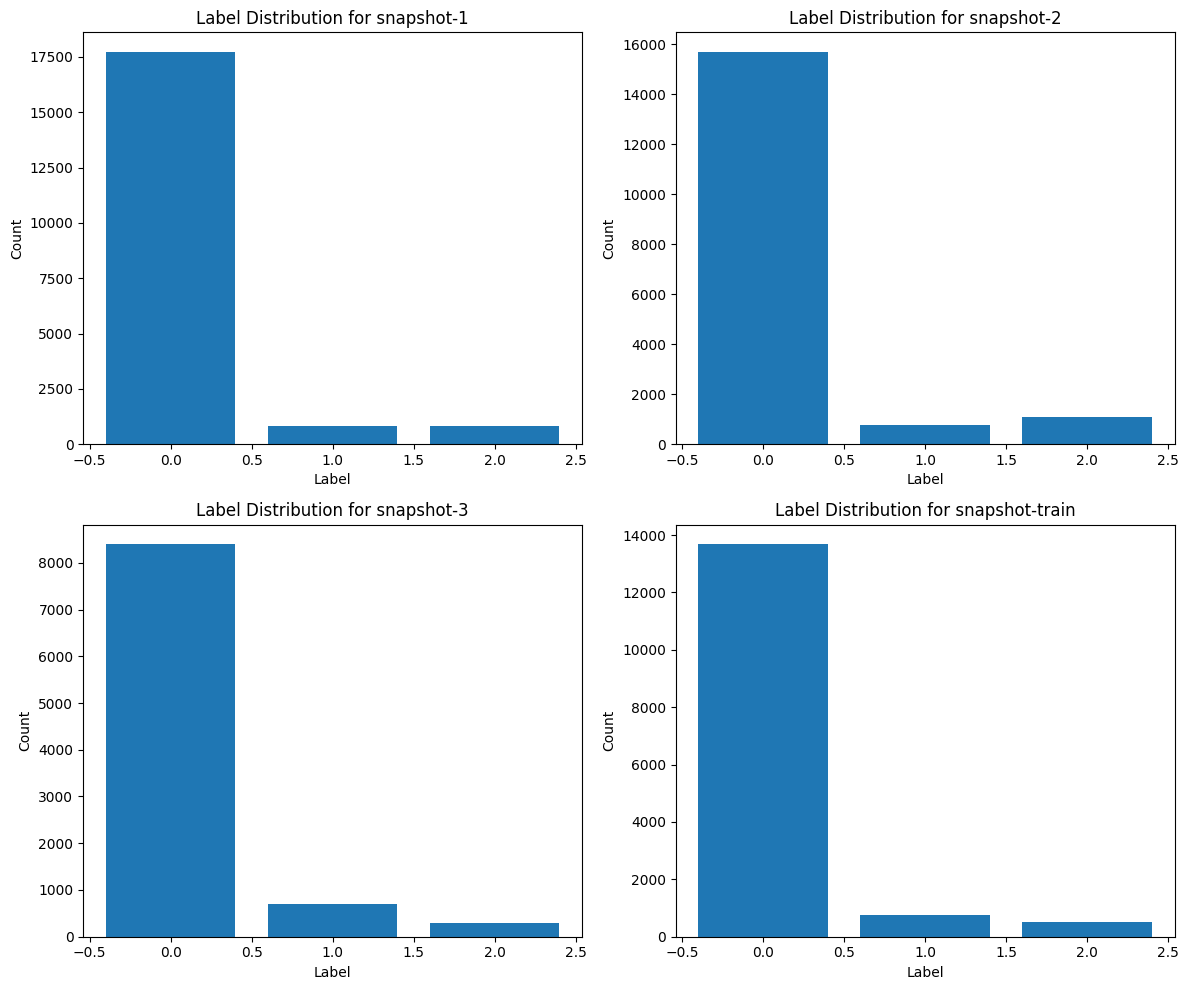

In [30]:
# Plot label distribution for each snapshot
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for i, snapshot in enumerate(["snapshot-1", "snapshot-2", "snapshot-3", "snapshot-train"]):
    if snapshot == "snapshot-train":
        data = snapshot_train
    else:
        data = pd.read_csv(f"../data/processed/qrels-{snapshot}-dctr.tsv", sep="\t", names=["query_id", "q0", "doc_id", "label"])
    label_counts = data["label"].value_counts().sort_index()
    axes[i//2, i%2].bar(label_counts.index, label_counts.values)
    axes[i//2, i%2].set_title(f"Label Distribution for {snapshot}")
    axes[i//2, i%2].set_xlabel("Label")
    axes[i//2, i%2].set_ylabel("Count")
plt.tight_layout()
plt.show()

In [26]:
def prepare_data(snapshots):
    names = {
        "train" : "Snapshot Train",
        1: "Snapshot 03-05",
        2: "Snapshot 06-08",
        3: "Snapshot 09-11"
    }
    data = {}
    for i, d in enumerate(snapshots):
        queries = d["query_id"].unique().tolist()
        data[names[list(names.keys())[i]]] = queries
    return data

In [27]:
data = prepare_data([snapshot_train, snapshot_1, snapshot_2, snapshot_3])

In [28]:
from upsetplot import from_contents
from upsetplot import UpSet

/workspaces/conf26-longeval-sci/.venv/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/workspaces/conf26-longeval-sci/.venv/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  style

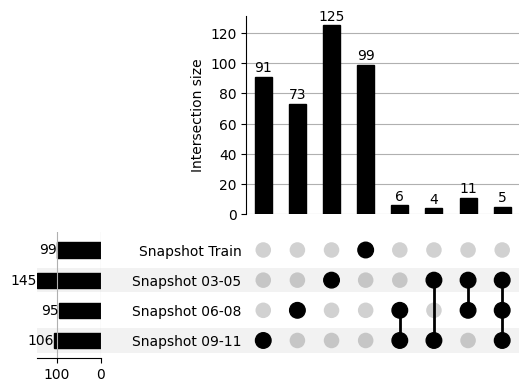

In [29]:
mysets = from_contents(data)
ax_dict = UpSet(mysets, sort_categories_by="-input",subset_size="count", show_counts=True).plot()